# 03 · Trades and quotes

Every trade and every NBBO quote from the consolidated tape (SIP). This is the most detailed
data Massive offers, and the largest: a single recent day is about 3.6 GB of trades and 10.5 GB
of quotes compressed, for all tickers together.

So tick data is **downloaded on demand**: the CLI fetches a full day's file, keeps only the
tickers you ask for, and discards the rest. This notebook uses AAPL, MSFT and SPY on
**2019-06-28**, which was also the annual Russell index reconstitution, one of the biggest
closing auctions of the year.

```bash
uv run subspace backfill history --dataset trades --start 2019-06-28 --symbols AAPL,MSFT,SPY
uv run subspace backfill history --dataset quotes --start 2019-06-28 --symbols AAPL,MSFT,SPY
```

Asking later for more tickers on the same day downloads the file again and merges.

1. trades: sizes, venues, condition codes
2. the closing auction, and rebuilding bars from trades
3. quotes: spreads and depth through the day
4. trades + quotes: classifying buys and sells

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl
from massive_subspace_stream import Store
from subspace_probe import style, timed

style()
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
pl.Config.set_fmt_table_cell_list_len(6)
store = Store()
NY = "America/New_York"
DAY = "2019-06-28"
TICKERS = ["AAPL", "MSFT", "SPY"]

In [2]:
with timed("trades + quotes for 3 tickers, one day"):
    trades = store.trades(TICKERS, start=DAY).with_columns(pl.col("conditions").fill_null([]))
    quotes = store.quotes(TICKERS, start=DAY)
print(f"{trades.height:,} trades, {quotes.height:,} quotes")
trades.head()

trades + quotes for 3 tickers, one day: 0.60 s
571,537 trades, 1,537,217 quotes


ticker,sip_timestamp,participant_timestamp,trf_timestamp,price,size,exchange,conditions,correction,id,sequence_number,tape,trf_id
str,"datetime[ns, UTC]","datetime[ns, UTC]","datetime[ns, UTC]",f64,f64,i16,list[i16],i8,str,i64,i8,i32
"""AAPL""",2019-06-28 08:00:00.020868356 UTC,2019-06-28 08:00:00.018985984 UTC,null,198.6,5.0,11,"[12, 37]",0,"""1""",1143,3,0
"""AAPL""",2019-06-28 08:00:00.020871200 UTC,2019-06-28 08:00:00.018992384 UTC,null,198.6,100.0,11,"[12, 41]",0,"""2""",1144,3,0
"""AAPL""",2019-06-28 08:00:00.020880275 UTC,2019-06-28 08:00:00.018992896 UTC,null,198.6,100.0,11,"[12, 41]",0,"""3""",1145,3,0
"""AAPL""",2019-06-28 08:00:00.020890262 UTC,2019-06-28 08:00:00.018995968 UTC,null,198.6,295.0,11,"[12, 41]",0,"""4""",1146,3,0
"""AAPL""",2019-06-28 08:00:00.020900917 UTC,2019-06-28 08:00:00.018996224 UTC,null,198.6,500.0,11,"[12, 41]",0,"""5""",1147,3,0


Trade columns: `sip_timestamp` (when the SIP published it, UTC, nanoseconds), `price`, `size`,
`exchange` (venue id), `conditions` (codes describing the trade), `trf_id` (which FINRA
facility reported an off-exchange trade), `sequence_number` (tape order).

## 1 · Trades

### Sizes
Most trades are small. **Odd lots** (fewer than 100 shares) are the majority of trades but a
much smaller share of volume.

In [3]:
trades.group_by("ticker").agg(
    pl.len().alias("trades"),
    pl.col("size").sum().alias("shares"),
    pl.col("size").median().alias("median_size"),
    ((pl.col("size") < 100).mean() * 100).round(1).alias("odd_lot_pct_of_trades"),
    (pl.col("size").filter(pl.col("size") < 100).sum() / pl.col("size").sum() * 100).round(1).alias("odd_lot_pct_of_volume"),
).sort("ticker")

ticker,trades,shares,median_size,odd_lot_pct_of_trades,odd_lot_pct_of_volume
str,u32,f64,f64,f64,f64
"""AAPL""",182097,3.9100849e7,94.0,51.1,8.2
"""MSFT""",142940,3.819142e7,100.0,41.2,4.8
"""SPY""",246500,6.9854532e7,100.0,25.5,2.7


### Venues
The `exchanges` reference table names each venue id. Id 4 ("FINRA Alternative Display
Facility") is where **off-exchange** trades appear: dark pools, wholesalers and internalized
retail orders, reported through a FINRA trade reporting facility.

In [4]:
venues = store.dataset("exchanges").select(pl.col("id").cast(pl.Int16).alias("exchange"), "name", "type")
by_venue = (
    trades.join(venues, on="exchange", how="left")
    .group_by("ticker", "name")
    .agg(pl.col("size").sum().alias("shares"))
    .with_columns((pl.col("shares") / pl.col("shares").sum().over("ticker") * 100).round(1).alias("pct"))
    .pivot(on="ticker", index="name", values="pct")
    .fill_null(0)
    .sort("AAPL", descending=True)
)
by_venue.head(10)

name,AAPL,SPY,MSFT
str,f64,f64,f64
"""Nasdaq""",55.7,17.4,55.8
"""FINRA Alternative Display Faci…",25.8,21.8,25.8
"""NYSE Arca, Inc.""",4.6,34.1,3.9
"""Cboe BZX""",4.0,8.5,5.2
"""Cboe EDGX""",2.9,5.7,2.6
"""Investors Exchange""",2.0,1.2,1.0
"""New York Stock Exchange""",1.4,2.8,1.6
"""Cboe BYX""",1.0,2.7,1.3
"""Nasdaq Texas, Inc.""",0.8,1.2,0.9


### Condition codes
Each trade carries zero or more condition codes. The `conditions` reference table names them
and says, through `update_rules`, whether a trade with that code counts toward a bar's
open/close, high/low and volume. For example, odd lots (37) add volume but do not set the high
or low, and the duplicate "official close" report (15) counts toward nothing.

In [5]:
conditions = (
    store.dataset("conditions")
    .filter(pl.col("data_types").list.contains("trade"))
    .with_columns(
        pl.col("update_rules").str.json_decode(
            pl.Struct({"consolidated": pl.Struct({"updates_high_low": pl.Boolean, "updates_open_close": pl.Boolean, "updates_volume": pl.Boolean})})
        ).struct.field("consolidated").alias("rules")
    )
    .select(pl.col("id").cast(pl.Int16).alias("condition"), "name", pl.col("rules").struct.unnest())
)
top_conditions = (
    trades.filter(pl.col("ticker") == "AAPL")
    .select("size", pl.col("conditions").alias("condition"))
    .explode("condition")
    .group_by("condition")
    .agg(pl.len().alias("trades"), pl.col("size").sum().alias("shares"))
    .join(conditions, on="condition", how="left")
    .sort("shares", descending=True)
)
top_conditions.head(12)

condition,trades,shares,name,updates_high_low,updates_open_close,updates_volume
i16,u32,f64,str,bool,bool,bool
41,72383,1.5132137e7,"""Trade Thru Exempt""",true,true,true
9,2,7.990072e6,"""Cross Trade""",true,true,true
15,2,7.755438e6,"""Market Center Official Close""",false,false,false
8,1,7.755338e6,"""Closing Prints""",true,true,true
14,71512,6.661412e6,"""Intermarket Sweep""",true,true,true
37,93076,3.201858e6,"""Odd Lot Trade""",false,false,true
12,3030,2.256735e6,"""Form T/Extended Hours""",false,false,true
2,206,1.655038e6,"""Average Price Trade""",false,false,true
13,165,1.143686e6,"""Extended Hours (Sold Out Of Se…",false,false,true


(A null condition means a plain regular-hours trade with no special codes.)

## 2 · The closing auction, and rebuilding bars from trades

The largest AAPL trades of the day:

In [6]:
trades.filter(pl.col("ticker") == "AAPL").sort("size", descending=True).head(5).select(
    pl.col("sip_timestamp").dt.convert_time_zone(NY).alias("ny_time"), "price", "size", "exchange", "conditions"
)

ny_time,price,size,exchange,conditions
"datetime[ns, America/New_York]",f64,f64,i16,list[i16]
2019-06-28 16:00:00.870542332 EDT,197.92,7.755338e6,12,"[8, 9, 41]"
2019-06-28 16:00:00.870554131 EDT,197.92,7.755338e6,12,[15]
2019-06-28 16:00:54.005956013 EDT,197.92,403332.0,4,[13]
2019-06-28 16:38:21.248922008 EDT,197.9214,318632.0,4,"[12, 2]"
2019-06-28 16:13:55.373405135 EDT,197.921,274500.0,4,"[12, 2]"


The closing cross on Nasdaq (exchange 12) printed **7.76 million shares at 16:00:00.87**, about
a quarter of AAPL's volume that day. It shows up twice: as the auction trade (codes 8 closing
print, 9 cross, 41 trade-through exempt) and again as the "official close" report (15), which
must not be counted twice.

Rebuilding bars from trades with the `update_rules` shows how the stored bars were made, and
where they differ:

In [7]:
def bar_eligibility(trades: pl.DataFrame, conditions: pl.DataFrame) -> pl.DataFrame:
    """Add updates_volume / updates_high_low / updates_open_close flags per trade.
    A trade counts only if every one of its condition codes allows it."""
    flags = ["updates_volume", "updates_high_low", "updates_open_close"]
    per_trade = (
        trades.with_row_index("_i")
        .select("_i", pl.col("conditions").alias("condition"))
        .explode("condition")
        .join(conditions.select("condition", *flags), on="condition", how="left")
        .group_by("_i")
        .agg([pl.col(f).fill_null(True).all() for f in flags])
    )
    # Trades with no condition codes have no rows above: they count for everything.
    return (
        trades.with_row_index("_i")
        .join(per_trade, on="_i", how="left")
        .with_columns(pl.col(flags).fill_null(True))
        .drop("_i")
        .sort("ticker", "sip_timestamp")
    )


def bars_from_trades(trades: pl.DataFrame) -> pl.DataFrame:
    t = trades.with_columns(pl.col("sip_timestamp").dt.truncate("1m").alias("timestamp"))
    oc, hl = pl.col("updates_open_close"), pl.col("updates_high_low")
    return (
        t.group_by("ticker", "timestamp")
        .agg(
            pl.col("price").filter(oc).first().alias("open"), pl.col("price").filter(hl).max().alias("high"),
            pl.col("price").filter(hl).min().alias("low"), pl.col("price").filter(oc).last().alias("close"),
            pl.col("size").filter(pl.col("updates_volume")).sum().alias("volume"),
        )
        .sort("ticker", "timestamp")
    )


eligible = bar_eligibility(trades, conditions)
rebuilt = bars_from_trades(eligible)
stored_min = store.bars(TICKERS, start=DAY, end=DAY, freq="1min")
stored_day = store.bars(TICKERS, start=DAY, end=DAY)

pl.DataFrame({
    "ticker": TICKERS,
    "all_trades": [trades.filter(pl.col("ticker") == t)["size"].sum() for t in TICKERS],
    "rebuilt_from_trades": [rebuilt.filter(pl.col("ticker") == t)["volume"].sum() for t in TICKERS],
    "stored_daily_bar": [stored_day.filter(pl.col("ticker") == t)["volume"].item() for t in TICKERS],
    "stored_minute_bars": [stored_min.filter(pl.col("ticker") == t)["volume"].sum() for t in TICKERS],
}).with_columns(pl.exclude("ticker").cast(pl.Int64))

ticker,all_trades,rebuilt_from_trades,stored_daily_bar,stored_minute_bars
str,i64,i64,i64,i64
"""AAPL""",39100849,31110642,30924799,22890143
"""MSFT""",38191420,30046899,29288159,21304010
"""SPY""",69854532,59666981,59323388,56767226


- Volume rebuilt with the update rules matches the **daily bar** closely.
- "All trades" is higher, because it double-counts the official-close report and similar
  duplicates.
- The **minute bars** are short by about the size of the closing auction. Minute by minute,
  rebuilt and stored volume agree except at 16:00 (AAPL: exactly the 7,755,438-share
  auction) and a few large after-hours prints:

In [8]:
cmp = rebuilt.join(stored_min.select("ticker", "timestamp", pl.col("volume").alias("stored")), on=["ticker", "timestamp"], how="full", coalesce=True).fill_null(0)
cmp = cmp.with_columns((pl.col("volume") - pl.col("stored")).alias("diff"))
print("minutes where rebuilt and stored volume differ by more than 1,000 shares:")
cmp.filter(pl.col("diff").abs() > 1000).with_columns(pl.col("timestamp").dt.convert_time_zone(NY).dt.strftime("%H:%M").alias("ny")).select(
    "ticker", "ny", pl.col("volume").cast(pl.Int64).alias("rebuilt"), pl.col("stored").cast(pl.Int64), pl.col("diff").cast(pl.Int64)
).sort("ticker", "ny")

minutes where rebuilt and stored volume differ by more than 1,000 shares:


ticker,ny,rebuilt,stored,diff
str,str,i64,i64,i64
"""AAPL""","""09:30""",487080,485200,1880
"""AAPL""","""16:00""",9001679,1246241,7755438
"""AAPL""","""16:15""",57863,659,57204
"""AAPL""","""16:16""",9001,0,9001
"""AAPL""","""16:23""",81375,41846,39529
"""AAPL""","""16:28""",193684,0,193684
"""AAPL""","""16:29""",60351,0,60351
"""AAPL""","""17:08""",17189,0,17189
"""AAPL""","""17:09""",78734,0,78734


In [9]:
reg_min = store.bars(TICKERS, start=DAY, end=DAY, freq="1min", session="regular")
both = reg_min.join(rebuilt, on=["ticker", "timestamp"], suffix="_rebuilt")
both.group_by("ticker").agg(
    pl.len().alias("regular_minutes"),
    *[((pl.col(c) - pl.col(f"{c}_rebuilt")).abs() < 0.005).mean().mul(100).round(1).alias(f"{c}_match_pct") for c in ("open", "high", "low", "close")],
).sort("ticker")

ticker,regular_minutes,open_match_pct,high_match_pct,low_match_pct,close_match_pct
str,u32,f64,f64,f64,f64
"""AAPL""",390,100.0,100.0,99.7,100.0
"""MSFT""",390,100.0,100.0,100.0,100.0
"""SPY""",390,100.0,99.7,99.5,100.0


Open, high, low and close of the rebuilt regular-session bars match the stored ones in
essentially every minute, so the update rules above are how Massive builds its bars; the only
real difference is which prints count toward minute volume.

**Practical rule** (also in notebook 02): take daily volume and the official close from daily
bars; minute bars do not include the closing auction.

## 3 · Quotes: spreads and depth

Each quote row is a new national best bid and offer (NBBO): the best bid and ask across all
exchanges, with their sizes. The quoted spread in basis points shows how expensive it is to
trade through the day:

In [10]:
regular = store.sessions(DAY).row(0, named=True)
q = (
    quotes.filter(
        pl.col("sip_timestamp").is_between(regular["market_open"], regular["market_close"]),
        pl.col("bid_price") > 0, pl.col("ask_price") > pl.col("bid_price"),
    )
    .with_columns(
        ((pl.col("ask_price") - pl.col("bid_price")) / ((pl.col("ask_price") + pl.col("bid_price")) / 2) * 1e4).alias("spread_bp"),
        (pl.col("ask_price") - pl.col("bid_price")).round(4).alias("spread_usd"),
        pl.col("sip_timestamp").dt.truncate("5m").alias("t5"),
    )
)
q.group_by("ticker").agg(
    pl.len().alias("quotes"),
    pl.col("spread_bp").median().round(2).alias("median_spread_bp"),
    (pl.col("spread_usd") <= 0.0101).mean().mul(100).round(1).alias("pct_at_one_cent"),
    pl.col("bid_size").median().alias("median_bid_size"),
    pl.col("ask_size").median().alias("median_ask_size"),
).sort("ticker")

ticker,quotes,median_spread_bp,pct_at_one_cent,median_bid_size,median_ask_size
str,u32,f64,f64,f64,f64
"""AAPL""",355188,0.51,67.1,300.0,300.0
"""MSFT""",425427,0.75,94.2,600.0,600.0
"""SPY""",609049,0.34,95.6,1900.0,1400.0


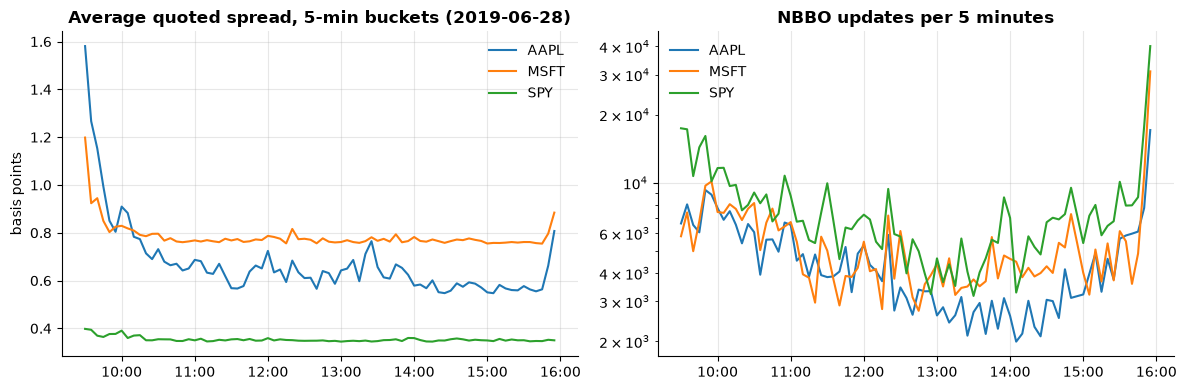

In [11]:
prof = q.group_by("ticker", "t5").agg(pl.col("spread_bp").mean(), pl.len().alias("updates")).sort("ticker", "t5")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
for (t,), g in prof.group_by("ticker", maintain_order=True):
    x = g["t5"].dt.convert_time_zone(NY).to_list()
    a1.plot(x, g["spread_bp"], label=t)
    a2.plot(x, g["updates"], label=t)
a1.set_title(f"Average quoted spread, 5-min buckets ({DAY})")
a1.set_ylabel("basis points")
a2.set_title("NBBO updates per 5 minutes")
a2.set_yscale("log")
for a in (a1, a2):
    a.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=x[0].tzinfo))
    a.legend()
fig.tight_layout()

Spreads are widest right after the open, when prices are still being discovered, and narrow
quickly. SPY trades at a one-cent spread almost all day, about 0.3 basis points.

## 4 · Trades + quotes: who initiated each trade?

Matching each trade with the quote in force just before it (an **as-of join**) tells whether
the trade happened at the ask (a buyer crossed the spread) or at the bid (a seller did). This is
the Lee-Ready rule, the standard way to sign trades when the data does not say who initiated
them.

In [12]:
nbbo = quotes.filter(pl.col("ask_price") > pl.col("bid_price"), pl.col("bid_price") > 0).select(
    "ticker", "sip_timestamp", "bid_price", "ask_price").sort("ticker", "sip_timestamp")
signed = (
    eligible.filter(pl.col("updates_volume"), pl.col("sip_timestamp").is_between(regular["market_open"], regular["market_close"]))
    .sort("ticker", "sip_timestamp")
    .join_asof(nbbo, on="sip_timestamp", by="ticker", strategy="backward", allow_exact_matches=False, check_sortedness=False)
    .with_columns(((pl.col("bid_price") + pl.col("ask_price")) / 2).alias("mid"))
    .with_columns(
        pl.when(pl.col("price") > pl.col("mid")).then(1).when(pl.col("price") < pl.col("mid")).then(-1).otherwise(0).alias("side"),
        (2 * (pl.col("price") - pl.col("mid")).abs() / pl.col("mid") * 1e4).alias("effective_spread_bp"),
    )
)
signed.group_by("ticker").agg(
    (pl.col("side") == 1).mean().mul(100).round(1).alias("buys_pct"),
    (pl.col("side") == -1).mean().mul(100).round(1).alias("sells_pct"),
    (pl.col("side") == 0).mean().mul(100).round(1).alias("at_mid_pct"),
    pl.col("effective_spread_bp").median().round(2).alias("median_effective_spread_bp"),
).sort("ticker")

ticker,buys_pct,sells_pct,at_mid_pct,median_effective_spread_bp
str,f64,f64,f64,f64
"""AAPL""",43.7,45.1,11.2,0.51
"""MSFT""",46.8,42.7,10.4,0.75
"""SPY""",43.4,46.7,10.0,0.34


Trades exactly at the midpoint are mostly off-exchange (midpoint dark pools and retail price
improvement).

For single stocks, signed volume (order flow) and price changes go together over short
horizons: in 5-minute buckets, more net buying comes with rising prices. SPY is the
exception, likely because its price follows index futures and arbitrage more than its own
order flow. Over a whole day the link is looser (chart below).

In [13]:
flow5 = (
    signed.filter(pl.col("updates_high_low"))
    .group_by("ticker", pl.col("sip_timestamp").dt.truncate("5m").alias("t5"))
    .agg((pl.col("side") * pl.col("size")).sum().alias("signed_volume"), pl.col("price").last().alias("last_price"))
    .sort("ticker", "t5")
    .with_columns(pl.col("last_price").log().diff().over("ticker").alias("ret"))
    .drop_nulls()
)
flow5.group_by("ticker").agg(pl.corr("signed_volume", "ret").round(2).alias("corr_flow_vs_return_5min")).sort("ticker")

ticker,corr_flow_vs_return_5min
str,f64
"""AAPL""",0.64
"""MSFT""",0.58
"""SPY""",0.06


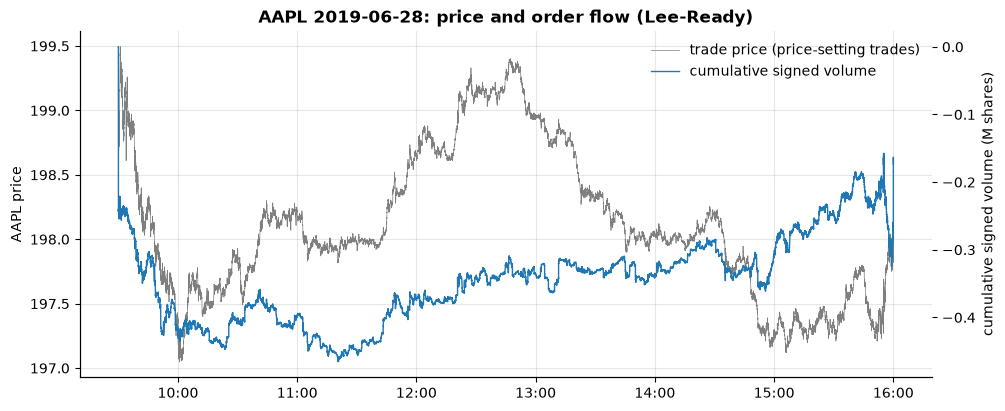

In [14]:
aapl = signed.filter(pl.col("ticker") == "AAPL", pl.col("updates_high_low")).with_columns(
    (pl.col("side") * pl.col("size")).cum_sum().alias("cum_flow"))
x = aapl["sip_timestamp"].dt.convert_time_zone(NY).to_list()
fig, ax = plt.subplots()
l1 = ax.plot(x, aapl["price"], lw=0.5, color="tab:gray", label="trade price (price-setting trades)")
ax.set_ylabel("AAPL price")
ax2 = ax.twinx()
l2 = ax2.plot(x, aapl["cum_flow"] / 1e6, color="tab:blue", lw=1, label="cumulative signed volume")
ax2.set_ylabel("cumulative signed volume (M shares)")
ax2.grid(False)
ax.set_title(f"AAPL {DAY}: price and order flow (Lee-Ready)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=x[0].tzinfo))
ax.legend(handles=l1 + l2, loc="upper right");

## Takeaways
- Download ticks per day and per symbol with the CLI; queries warn when a day or symbol is
  missing.
- Use the `conditions` table's update rules whenever you aggregate trades yourself.
- `join_asof` on `sip_timestamp` lines trades up with the prevailing quote, the basis for
  spreads, trade signing and execution-cost analysis.

Next: **04 · Reference data and fundamentals**.